# Groverjev algoritem: idealni simulator, digitalni dvojcki in IBM procesor

Za vsak $n$ (in vsako optimizacijsko stopnjo transpilerja) zgradimo Groverjevo vezje z oraclom za znano
oznaceno stanje, ga **enkrat** prevedemo za procesor in isto prevedeno vezje pozenemo idealno, na dvojckih
in na realnem procesorju. Pomozne funkcije so v `grover_ibm.py`.

**Dvojcki:** vsi uporabljajo isto standardno konstrukcijo Qiskit Aer (`NoiseModel.from_backend`) in
upostevajo cakanje kubitov (vezja so razporejena, cakanje je ukaz `delay`). Razlikujejo se samo po izvoru
kalibracije:

| vir | kalibracija |
|---|---|
| `twin_backend` | posnetek zive kalibracije ob gradnji vezij (`<TAG>_live_calibration.csv`) |
| `twin_csv` | CSV, prenesen s platforme IBM (`calibration/`) |
| `twin_fake` | `FakeMarrakesh` (star posnetek v `qiskit_ibm_runtime`) |
| `twin_csv_noidle` | kontrola: kot `twin_csv`, a brez cakanja |

**Uporaba:** celice so neodvisni koraki. V razdelku 1 pozeni **eno** od celic (nova *ali* shranjena vezja).
Celoten zagon: 0 -> 1 (nova vezja) -> 2 (poslji) -> 3 (simulacije, medtem naloga caka v vrsti) -> 4 -> 5.

In [1]:
BACKEND = "ibm_marrakesh"
NS = [2, 3, 4, 5, 6]         # stevila kubitov
OPTS = [1, 3]                # optimizacijske stopnje transpilerja
SHOTS = 10000                # QPU
SIM_SHOTS = 10000            # simulacije
SEED = 7                     # seme za izbiro oznacenih stanj
TARGET_MODE = "random"       # "random" ali "ones"
OUTDIR = "results"

In [2]:
import json
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from qiskit import qpy, transpile
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

from grover_ibm import (SOURCES, TWINS, csv_twin, find_csv, get_backend, grover_circuit,
                        ideal_probability, normalize, run_counts, save_calibration_csv,
                        schedule_alap, twin_from_backend, two_qubit_count, weighted_jaccard)

out = Path(OUTDIR)
out.mkdir(parents=True, exist_ok=True)

# prazne zacetne vrednosti; pravo vsebino nastavi razdelek 1 (vezja)
items: list = []
results: dict = {}
circ_df = pd.DataFrame()


def p_target(name):
    return [normalize(c).get(it["target"], 0.0) for c, it in zip(results[name], items)]


def p_table():
    df = circ_df[["n", "opt", "target", "two_q", "P_theory"]].copy()
    df["random"] = [1 / 2 ** n for n in df["n"]]
    for name in SOURCES:
        if name in results:
            df[f"P_{name}"] = p_target(name)
    return df.round(4)


def hist(name, n, opt):
    i = next(j for j, it in enumerate(items) if it["n"] == n and it["opt"] == opt)
    return plot_histogram(results[name][i], title=f"{name}: n={n}, opt={opt}, target={items[i]['target']}",
                          figsize=(8, 3), bar_labels=False)

## 0. Procesor

In [3]:
# pravi procesor (potrebuje IBM_KEY v .env)
service, backend = get_backend(BACKEND)
print("backend:", backend.name)

qiskit_runtime_service._discover_account:WARNING:2026-11-22 18:47:27,089: Loading account with the given token. A saved account will not be used.


[backendi] ['ibm_fez', 'ibm_kingston', 'ibm_marrakesh']
backend: ibm_marrakesh


## 1. Vezja

Pozeni **eno** od obeh celic. Obe izpraznita slovar `results` v pomnilniku (rezultati simulacij, ki se
nanasajo na prejsnja vezja); datoteke v `results/` ostanejo nespremenjene.

* **nova vezja**: zgradi, prevede in shrani pod novo oznako (`TAG`), skupaj s **posnetkom zive kalibracije**
  (iste, ki jo je uporabil transpiler pri izbiri kubitov),
* **shranjena vezja**: nalozi vezja z dano oznako - uporabi za analizo ze poslane QPU naloge,
  da so vezja enaka tistim na procesorju.

In [4]:
# nova vezja
TAG = time.strftime("%Y%m%d-%H%M%S")
qpy_path, meta_path = out / f"{TAG}_circuits.qpy", out / f"{TAG}_meta.json"
rng = random.Random(SEED)
items, isa_list, logical = [], [], {}
for n in NS:
    target = "1" * n if TARGET_MODE == "ones" else "".join(rng.choice("01") for _ in range(n))
    qc, k = grover_circuit(n, target)
    logical[n] = qc
    layout = None                      # prvi opt izbere kubite, ostali jih prevzamejo
    for opt in OPTS:
        isa = transpile(qc, backend=backend, optimization_level=opt, seed_transpiler=1,
                        initial_layout=layout)
        if layout is None:
            layout = isa.layout.initial_index_layout(filter_ancillas=True)
        items.append(dict(
            n=n, opt=opt, target=target, k=k, layout=layout,
            pre=dict(qubits=qc.num_qubits, depth=qc.decompose(reps=3).depth(),
                     ops={a: int(b) for a, b in qc.count_ops().items()}),
            post=dict(depth=isa.depth(), two_q=two_qubit_count(isa),
                      ops={a: int(b) for a, b in isa.count_ops().items()}),
            ideal=ideal_probability(n, k)))
        isa_list.append(isa)
with open(qpy_path, "wb") as f:
    qpy.dump(isa_list, f)
live_csv = out / f"{TAG}_live_calibration.csv"
live_time = save_calibration_csv(backend, live_csv)
meta = dict(backend=backend.name, shots=SHOTS, seed=SEED, items=items,
            csv=find_csv(BACKEND), live_csv=str(live_csv), live_time=str(live_time), job_id=None)
json.dump(meta, open(meta_path, "w"), indent=1)
results = {}
print(f"tag={TAG}: {len(isa_list)} vezij shranjenih v {qpy_path}")
print(f"posnetek kalibracije ({live_time}) shranjen v {live_csv}")

tag=20261122-184732: 10 vezij shranjenih v results/20261122-184732_circuits.qpy
posnetek kalibracije (2026-11-22 18:26:41+01:00) shranjen v results/20261122-184732_live_calibration.csv


In [ ]:
# shranjena vezja (vpisi oznako)
TAG = "20261122-184732"
qpy_path, meta_path = out / f"{TAG}_circuits.qpy", out / f"{TAG}_meta.json"
meta = json.load(open(meta_path))
with open(qpy_path, "rb") as f:
    isa_list = qpy.load(f)
items = meta["items"]
logical = {it["n"]: grover_circuit(it["n"], it["target"])[0] for it in items}
results = {}
print(f"tag={TAG}: {len(isa_list)} vezij, backend={meta['backend']}, job_id={meta.get('job_id')}")

In [5]:
circ_df = pd.DataFrame([dict(n=it["n"], opt=it["opt"], target=it["target"], k=it["k"],
                             depth_pre=it["pre"]["depth"], depth_post=it["post"]["depth"],
                             two_q=it["post"]["two_q"], P_theory=round(it["ideal"], 4))
                        for it in items])
circ_df

,n,opt,target,k,depth_pre,depth_post,two_q,P_theory
0,2,1,10,1,12,12,2,1.0000
1,2,3,10,1,12,9,2,1.0000
2,3,1,100,2,58,169,45,0.9453
3,3,3,100,2,58,135,37,0.9453
4,4,1,0100,3,178,662,189,0.9613
5,4,3,0100,3,178,495,163,0.9613
6,5,1,00110,4,690,1841,549,0.9992
7,5,3,00110,4,690,1441,517,0.9992
8,6,1,001000,6,1539,5305,2073,0.9966
9,6,3,001000,6,1539,4334,1773,0.9966


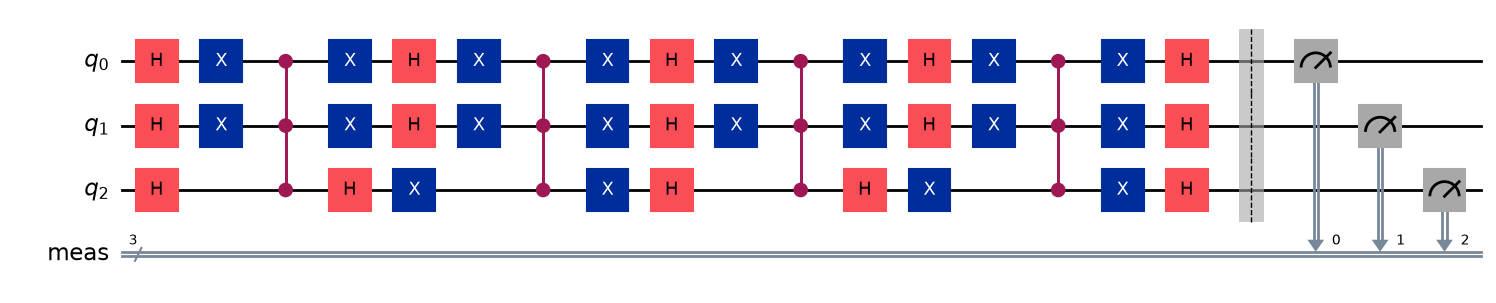

In [6]:
# logicno vezje za n=3 (pred prevajanjem)
logical[3].draw("mpl", fold=-1)

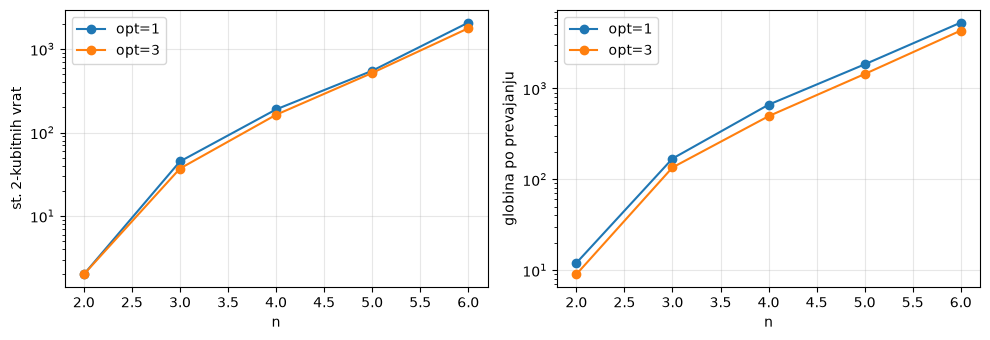

In [7]:
# rast stevila 2-kubitnih vrat in globine po prevajanju
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
for opt, g in circ_df.groupby("opt"):
    axs[0].plot(g["n"], g["two_q"], "o-", label=f"opt={opt}")
    axs[1].plot(g["n"], g["depth_post"], "o-", label=f"opt={opt}")
axs[0].set(xlabel="n", ylabel="st. 2-kubitnih vrat", yscale="log")
axs[1].set(xlabel="n", ylabel="globina po prevajanju", yscale="log")
for ax in axs:
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()

## 2. Realni procesor: posiljanje

* **poslji nalogo**: porabi cas na QPU. Ce imajo trenutna vezja ze znan `job_id` (v `*_meta.json`),
  nove naloge ne poslje, ampak uporabi obstojeco. ID nove naloge se takoj shrani v meta datoteko.
  Poslji takoj po gradnji vezij, da je posnetek kalibracije cim blizje casu izvedbe.
* **nalozi nalogo**: poveze se z nalogo iz meta datoteke (za to najprej nalozi shranjena vezja v razdelku 1).

In [8]:
# poslji nalogo
from qiskit_ibm_runtime import SamplerV2
if meta.get("job_id"):
    job = service.job(meta["job_id"])
    print(f"vezja s tag={TAG} so ze bila poslana (job id {meta['job_id']}, status {job.status()}); "
          "nove naloge ne posiljam.")
else:
    st = backend.status()
    print(f"{backend.name}: operational={st.operational} status_msg={st.status_msg!r} "
          f"pending_jobs={st.pending_jobs}")
    if not st.operational or st.status_msg != "active":
        raise RuntimeError(f"{backend.name} ni aktiven; poskusi pozneje.")
    job = SamplerV2(mode=backend).run(isa_list, shots=SHOTS)
    meta["job_id"] = job.job_id()
    json.dump(meta, open(meta_path, "w"), indent=1)
    print(f"job id: {job.job_id()} (shranjen v {meta_path})")

ibm_marrakesh: operational=True status_msg='active' pending_jobs=0
job id: dc1ilganj2vs73dfdb8g (shranjen v results/20261122-184732_meta.json)


In [9]:
# nalozi nalogo iz meta datoteke
if not meta.get("job_id"):
    raise RuntimeError(f"tag={TAG} nima shranjenega job_id")
job = service.job(meta["job_id"])
print(f"job id: {job.job_id()}, status: {job.status()}")

job id: dc1ilganj2vs73dfdb8g, status: RUNNING


## 3. Simulacije

Vsaka celica doda svoj vir v `results` in izpise tabelo $P(\text{oznaceno stanje})$ za vse vire do zdaj.
Simulacije lahko tecejo, medtem ko naloga caka v vrsti.

### 3a. Idealni simulator (brez suma)

In [10]:
t0 = time.time()
results["ideal"] = run_counts(AerSimulator(), isa_list, SIM_SHOTS, 1)
print(f"{time.time() - t0:.1f} s")
p_table()

0.3 s


,n,opt,target,two_q,P_theory,random,P_ideal
0,2,1,10,2,1.0000,0.2500,1.0000
1,2,3,10,2,1.0000,0.2500,1.0000
2,3,1,100,45,0.9453,0.1250,0.9435
3,3,3,100,37,0.9453,0.1250,0.9464
4,4,1,0100,189,0.9613,0.0625,0.9605
5,4,3,0100,163,0.9613,0.0625,0.9610
6,5,1,00110,549,0.9992,0.0312,0.9993
7,5,3,00110,517,0.9992,0.0312,0.9992
8,6,1,001000,2073,0.9966,0.0156,0.9961
9,6,3,001000,1773,0.9966,0.0156,0.9964


### 3b. Dvojcek iz zive kalibracije (`twin_backend`)

Posnetek kalibracije, shranjen ob gradnji vezij. Drugi zagon z drugim semenom (`twin_backend_b`) je kontrola
vzorcenja: Jaccard med njima (`J_baseline`) je zgornja meja, ki jo dopusca koncno stevilo ponovitev.

In [11]:
live_csv = meta.get("live_csv")
if not (live_csv and Path(live_csv).exists()):
    raise FileNotFoundError(f"oznaka {TAG} nima posnetka zive kalibracije (starejsi zagoni)")
t0 = time.time()
sim, tgt = csv_twin(live_csv)
sched = schedule_alap(isa_list, tgt)
results["twin_backend"] = run_counts(sim, sched, SIM_SHOTS, 1)
results["twin_backend_b"] = run_counts(sim, sched, SIM_SHOTS, 2)
print(f"{time.time() - t0:.1f} s (kalibracija {meta['live_time']})")
p_table()

[CSV] kubiti z manjkajocimi podatki (manjkajoce vrednosti iz fake_marrakesh): [82, 94, 130]
16.1 s (kalibracija 2026-11-22 18:26:41+01:00)


,n,opt,target,two_q,P_theory,random,P_ideal,P_twin_backend,P_twin_backend_b
0,2,1,10,2,1.0000,0.2500,1.0000,0.9310,0.9323
1,2,3,10,2,1.0000,0.2500,1.0000,0.9277,0.9333
2,3,1,100,45,0.9453,0.1250,0.9435,0.7896,0.7867
3,3,3,100,37,0.9453,0.1250,0.9464,0.8067,0.8053
4,4,1,0100,189,0.9613,0.0625,0.9605,0.4716,0.4785
5,4,3,0100,163,0.9613,0.0625,0.9610,0.5431,0.5494
6,5,1,00110,549,0.9992,0.0312,0.9993,0.1221,0.1301
7,5,3,00110,517,0.9992,0.0312,0.9992,0.1369,0.1400
8,6,1,001000,2073,0.9966,0.0156,0.9961,0.0143,0.0171
9,6,3,001000,1773,0.9966,0.0156,0.9964,0.0154,0.0156


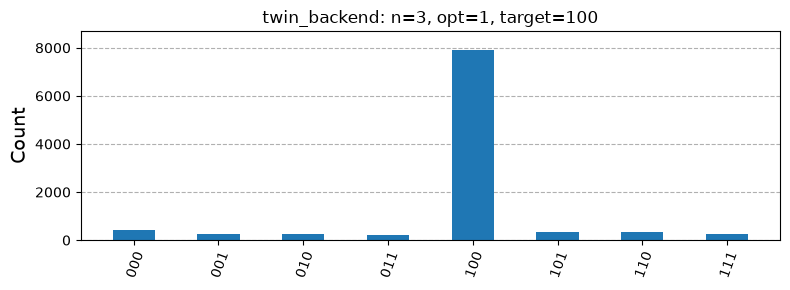

In [12]:
hist("twin_backend", 3, OPTS[0])

### 3c. Dvojcek iz prenesenega CSV (`twin_csv`) in kontrola brez cakanja (`twin_csv_noidle`)

CSV s platforme IBM, zapisan v meta datoteki ob gradnji vezij. Kontrola uporabi isti model na nerazporejenih
vezjih, torej brez suma med cakanjem - razlika med obema pokaze vpliv cakanja kubitov.

In [13]:
csv_path = meta["csv"]
if not (csv_path and Path(csv_path).exists()):
    raise FileNotFoundError(f"kalibracijski CSV ni najden: {csv_path!r} (pricakovan v calibration/)")
t0 = time.time()
sim, tgt = csv_twin(csv_path)
results["twin_csv"] = run_counts(sim, schedule_alap(isa_list, tgt), SIM_SHOTS, 1)
results["twin_csv_noidle"] = run_counts(sim, isa_list, SIM_SHOTS, 1)
print(f"{time.time() - t0:.1f} s ({csv_path})")
p_table()

[CSV] kubiti z manjkajocimi podatki (manjkajoce vrednosti iz fake_marrakesh): [82, 94, 113, 119, 130]
13.5 s (calibration/ibm_marrakesh_calibrations_2026-11-22T17_26_41Z.csv)


,n,opt,target,two_q,P_theory,random,P_ideal,P_twin_backend,P_twin_backend_b,P_twin_csv,P_twin_csv_noidle
0,2,1,10,2,1.0000,0.2500,1.0000,0.9310,0.9323,0.9310,0.9310
1,2,3,10,2,1.0000,0.2500,1.0000,0.9277,0.9333,0.9277,0.9277
2,3,1,100,45,0.9453,0.1250,0.9435,0.7896,0.7867,0.7896,0.8120
3,3,3,100,37,0.9453,0.1250,0.9464,0.8067,0.8053,0.8067,0.8230
4,4,1,0100,189,0.9613,0.0625,0.9605,0.4716,0.4785,0.4716,0.6094
5,4,3,0100,163,0.9613,0.0625,0.9610,0.5431,0.5494,0.5431,0.6680
6,5,1,00110,549,0.9992,0.0312,0.9993,0.1221,0.1301,0.1221,0.2150
7,5,3,00110,517,0.9992,0.0312,0.9992,0.1369,0.1400,0.1369,0.2272
8,6,1,001000,2073,0.9966,0.0156,0.9961,0.0143,0.0171,0.0143,0.0209
9,6,3,001000,1773,0.9966,0.0156,0.9964,0.0154,0.0156,0.0154,0.0289


### 3d. Dvojcek Fake backend (`twin_fake`)

Kalibracija, shranjena v `qiskit_ibm_runtime` (`FakeMarrakesh`, starejsi posnetek).

In [14]:
from qiskit_ibm_runtime.fake_provider import FakeMarrakesh
t0 = time.time()
sim, tgt = twin_from_backend(FakeMarrakesh())
results["twin_fake"] = run_counts(sim, schedule_alap(isa_list, tgt), SIM_SHOTS, 1)
print(f"{time.time() - t0:.1f} s")
p_table()

9.6 s


,n,opt,target,two_q,P_theory,random,P_ideal,P_twin_backend,P_twin_backend_b,P_twin_csv,P_twin_csv_noidle,P_twin_fake
0,2,1,10,2,1.0000,0.2500,1.0000,0.9310,0.9323,0.9310,0.9310,0.9794
1,2,3,10,2,1.0000,0.2500,1.0000,0.9277,0.9333,0.9277,0.9277,0.9773
2,3,1,100,45,0.9453,0.1250,0.9435,0.7896,0.7867,0.7896,0.8120,0.7625
3,3,3,100,37,0.9453,0.1250,0.9464,0.8067,0.8053,0.8067,0.8230,0.7774
4,4,1,0100,189,0.9613,0.0625,0.9605,0.4716,0.4785,0.4716,0.6094,0.3483
5,4,3,0100,163,0.9613,0.0625,0.9610,0.5431,0.5494,0.5431,0.6680,0.3919
6,5,1,00110,549,0.9992,0.0312,0.9993,0.1221,0.1301,0.1221,0.2150,0.0947
7,5,3,00110,517,0.9992,0.0312,0.9992,0.1369,0.1400,0.1369,0.2272,0.1051
8,6,1,001000,2073,0.9966,0.0156,0.9961,0.0143,0.0171,0.0143,0.0209,0.0142
9,6,3,001000,1773,0.9966,0.0156,0.9964,0.0154,0.0156,0.0154,0.0289,0.0149


## 4. Realni procesor: rezultat

`job.result()` caka, dokler naloga ni koncana; stetja se takoj shranijo v `<TAG>_qpu_counts.json`.

In [15]:
# rezultat (caka na zakljucek naloge)
t0 = time.time()
res = job.result()
results["qpu"] = [r.data.meas.get_counts() for r in res]
qpu_path = out / f"{TAG}_qpu_counts.json"
json.dump(dict(job_id=job.job_id(), backend=meta["backend"], shots=SHOTS,
               items=[dict(n=it["n"], opt=it["opt"], target=it["target"]) for it in items],
               counts=results["qpu"]), open(qpu_path, "w"), indent=1)
print(f"QPU stetja shranjena v {qpu_path}")
print(f"cakanje: {time.time() - t0:.1f} s")
try:
    print("metrics:", job.metrics())
except Exception as e:
    print("metrics() ni na voljo:", e)
p_table()

QPU stetja shranjena v results/20261122-184732_qpu_counts.json
cakanje: 1.3 s
metrics: {'caller': 'qiskit', 'qiskit_version': 'qiskit_ibm_runtime-0.52.1,qiskit-2.6.2*,qiskit_aer-0.18.2*', 'timestamps': {'created': '2026-11-22T17:47:46.122114Z', 'finished': '2026-11-22T17:48:28.527346Z', 'running': '2026-11-22T17:47:48.079639Z'}, 'usage': {'qpu_charge_time_seconds': 34, 'value': 0.55008, 'unit': 'resource_units', 'status': 'complete', 'details': [{'value': 0.55008, 'unit': 'resource_units', 'metric': {'id': 'caffe3ca-729c-5750-8777-df63bbf8bfd9', 'value': 34}}]}, 'circuits_execution_time_ns': 31284138496}


,n,opt,target,two_q,P_theory,random,P_ideal,P_twin_backend,P_twin_backend_b,P_twin_csv,P_twin_csv_noidle,P_twin_fake,P_qpu
0,2,1,10,2,1.0000,0.2500,1.0000,0.9310,0.9323,0.9310,0.9310,0.9794,0.9585
1,2,3,10,2,1.0000,0.2500,1.0000,0.9277,0.9333,0.9277,0.9277,0.9773,0.9552
2,3,1,100,45,0.9453,0.1250,0.9435,0.7896,0.7867,0.7896,0.8120,0.7625,0.6972
3,3,3,100,37,0.9453,0.1250,0.9464,0.8067,0.8053,0.8067,0.8230,0.7774,0.7033
4,4,1,0100,189,0.9613,0.0625,0.9605,0.4716,0.4785,0.4716,0.6094,0.3483,0.3895
5,4,3,0100,163,0.9613,0.0625,0.9610,0.5431,0.5494,0.5431,0.6680,0.3919,0.4617
6,5,1,00110,549,0.9992,0.0312,0.9993,0.1221,0.1301,0.1221,0.2150,0.0947,0.1007
7,5,3,00110,517,0.9992,0.0312,0.9992,0.1369,0.1400,0.1369,0.2272,0.1051,0.1064
8,6,1,001000,2073,0.9966,0.0156,0.9961,0.0143,0.0171,0.0143,0.0209,0.0142,0.0156
9,6,3,001000,1773,0.9966,0.0156,0.9964,0.0154,0.0156,0.0154,0.0289,0.0149,0.0174


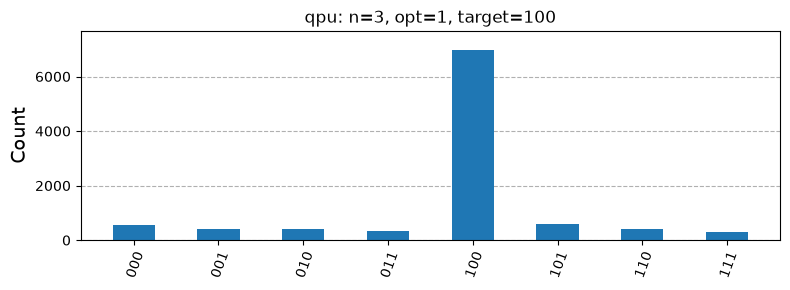

In [16]:
hist("qpu", 3, OPTS[0])

## 5. Povzetek

Uporabi vse vire, ki so trenutno v `results`. $J(p,q)=\sum_x\min(p_x,q_x)/\sum_x\max(p_x,q_x)$ je utezeni
Jaccard med dvojckom in QPU; `J_baseline` je Jaccard med dvema zagonoma istega dvojcka (meja zaradi vzorcenja).

In [17]:
rows = []
for i, it in enumerate(items):
    t = it["target"]
    row = dict(n=it["n"], opt=it["opt"], target=t, k=it["k"], two_q=it["post"]["two_q"],
               depth=it["post"]["depth"], random=1 / 2 ** it["n"], ideal_theory=it["ideal"])
    for name in SOURCES:
        if name in results:
            row[f"P_{name}"] = normalize(results[name][i]).get(t, 0.0)
    if "qpu" in results:
        q = normalize(results["qpu"][i])
        for name in TWINS:
            if name in results:
                row[f"J_{name}"] = weighted_jaccard(normalize(results[name][i]), q)
    if "twin_backend" in results and "twin_backend_b" in results:
        row["J_baseline"] = weighted_jaccard(normalize(results["twin_backend"][i]),
                                             normalize(results["twin_backend_b"][i]))
    rows.append(row)

summary = pd.DataFrame(rows)
summary.to_csv(out / f"{TAG}_summary.csv", index=False)
json.dump(results, open(out / f"{TAG}_counts.json", "w"))
print(f"shranjeno v {out}/ (oznaka {TAG}); viri: {list(results)}")
summary.round(4)

shranjeno v results/ (oznaka 20261122-184732); viri: ['ideal', 'twin_backend', 'twin_backend_b', 'twin_csv', 'twin_csv_noidle', 'twin_fake', 'qpu']


,n,opt,target,k,two_q,depth,random,ideal_theory,P_ideal,P_twin_backend,P_twin_backend_b,P_twin_csv,P_twin_csv_noidle,P_twin_fake,P_qpu,J_twin_backend,J_twin_csv,J_twin_csv_noidle,J_twin_fake,J_baseline
0,2,1,10,1,2,12,0.2500,1.0000,1.0000,0.9310,0.9323,0.9310,0.9310,0.9794,0.9585,0.9286,0.9286,0.9286,0.9591,0.9974
1,2,3,10,1,2,9,0.2500,1.0000,1.0000,0.9277,0.9333,0.9277,0.9277,0.9773,0.9552,0.9231,0.9231,0.9231,0.9568,0.9889
2,3,1,100,2,45,169,0.1250,0.9453,0.9435,0.7896,0.7867,0.7896,0.8120,0.7625,0.6972,0.8308,0.8308,0.7940,0.8610,0.9826
3,3,3,100,2,37,135,0.1250,0.9453,0.9464,0.8067,0.8053,0.8067,0.8230,0.7774,0.7033,0.8126,0.8126,0.7862,0.8541,0.9910
4,4,1,0100,3,189,662,0.0625,0.9613,0.9605,0.4716,0.4785,0.4716,0.6094,0.3483,0.3895,0.8450,0.8450,0.6395,0.8786,0.9631
5,4,3,0100,3,163,495,0.0625,0.9613,0.9610,0.5431,0.5494,0.5431,0.6680,0.3919,0.4617,0.8408,0.8408,0.6580,0.8471,0.9687
6,5,1,00110,4,549,1841,0.0312,0.9992,0.9993,0.1221,0.1301,0.1221,0.2150,0.0947,0.1007,0.8737,0.8737,0.7384,0.8589,0.9363
7,5,3,00110,4,517,1441,0.0312,0.9992,0.9992,0.1369,0.1400,0.1369,0.2272,0.1051,0.1064,0.8493,0.8493,0.7128,0.8657,0.9451
8,6,1,001000,6,2073,5305,0.0156,0.9966,0.9961,0.0143,0.0171,0.0143,0.0209,0.0142,0.0156,0.8855,0.8855,0.8572,0.8697,0.9179
9,6,3,001000,6,1773,4334,0.0156,0.9966,0.9964,0.0154,0.0156,0.0154,0.0289,0.0149,0.0174,0.8857,0.8857,0.8549,0.8758,0.9066


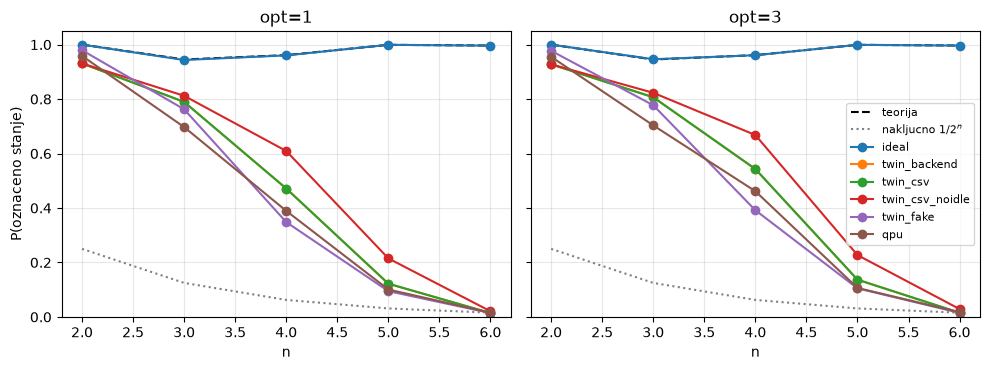

In [18]:
opts = sorted(summary["opt"].unique())
fig, axs = plt.subplots(1, len(opts), figsize=(5 * len(opts), 3.8), sharey=True, squeeze=False)
for ax, opt in zip(axs[0], opts):
    g = summary[summary["opt"] == opt]
    ax.plot(g["n"], g["ideal_theory"], "k--", label="teorija")
    ax.plot(g["n"], g["random"], ":", color="gray", label="nakljucno $1/2^n$")
    for c in summary.columns:
        if c.startswith("P_") and c != "P_twin_backend_b":
            ax.plot(g["n"], g[c], "o-", label=c[2:])
    ax.set(title=f"opt={opt}", xlabel="n", ylim=(0, 1.05))
    ax.grid(alpha=0.3)
axs[0][0].set_ylabel("P(oznaceno stanje)")
axs[0][-1].legend(fontsize=8)
plt.tight_layout()

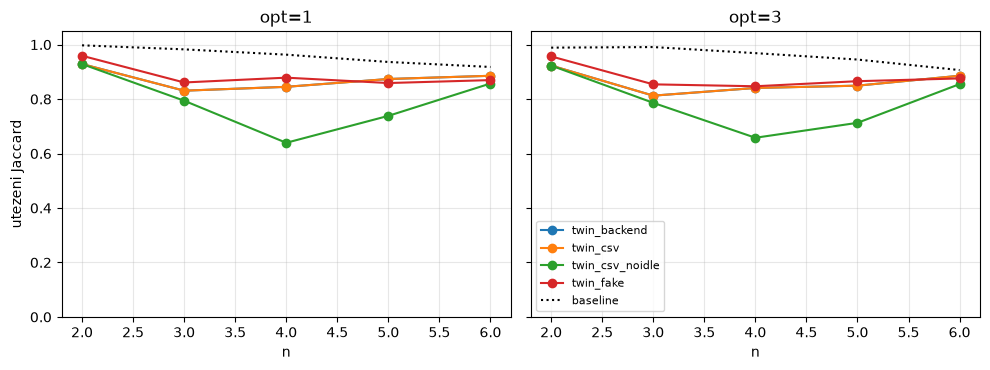

In [19]:
# Jaccard dvojcek vs QPU (potrebuje QPU rezultat)
jcols = [c for c in summary.columns if c.startswith("J_")]
fig, axs = plt.subplots(1, len(opts), figsize=(5 * len(opts), 3.8), sharey=True, squeeze=False)
for ax, opt in zip(axs[0], opts):
    g = summary[summary["opt"] == opt]
    for c in jcols:
        ax.plot(g["n"], g[c], "k:" if c == "J_baseline" else "o-", label=c[2:])
    ax.set(title=f"opt={opt}", xlabel="n", ylim=(0, 1.05))
    ax.grid(alpha=0.3)
axs[0][0].set_ylabel("utezeni Jaccard")
axs[0][-1].legend(fontsize=8)
plt.tight_layout()

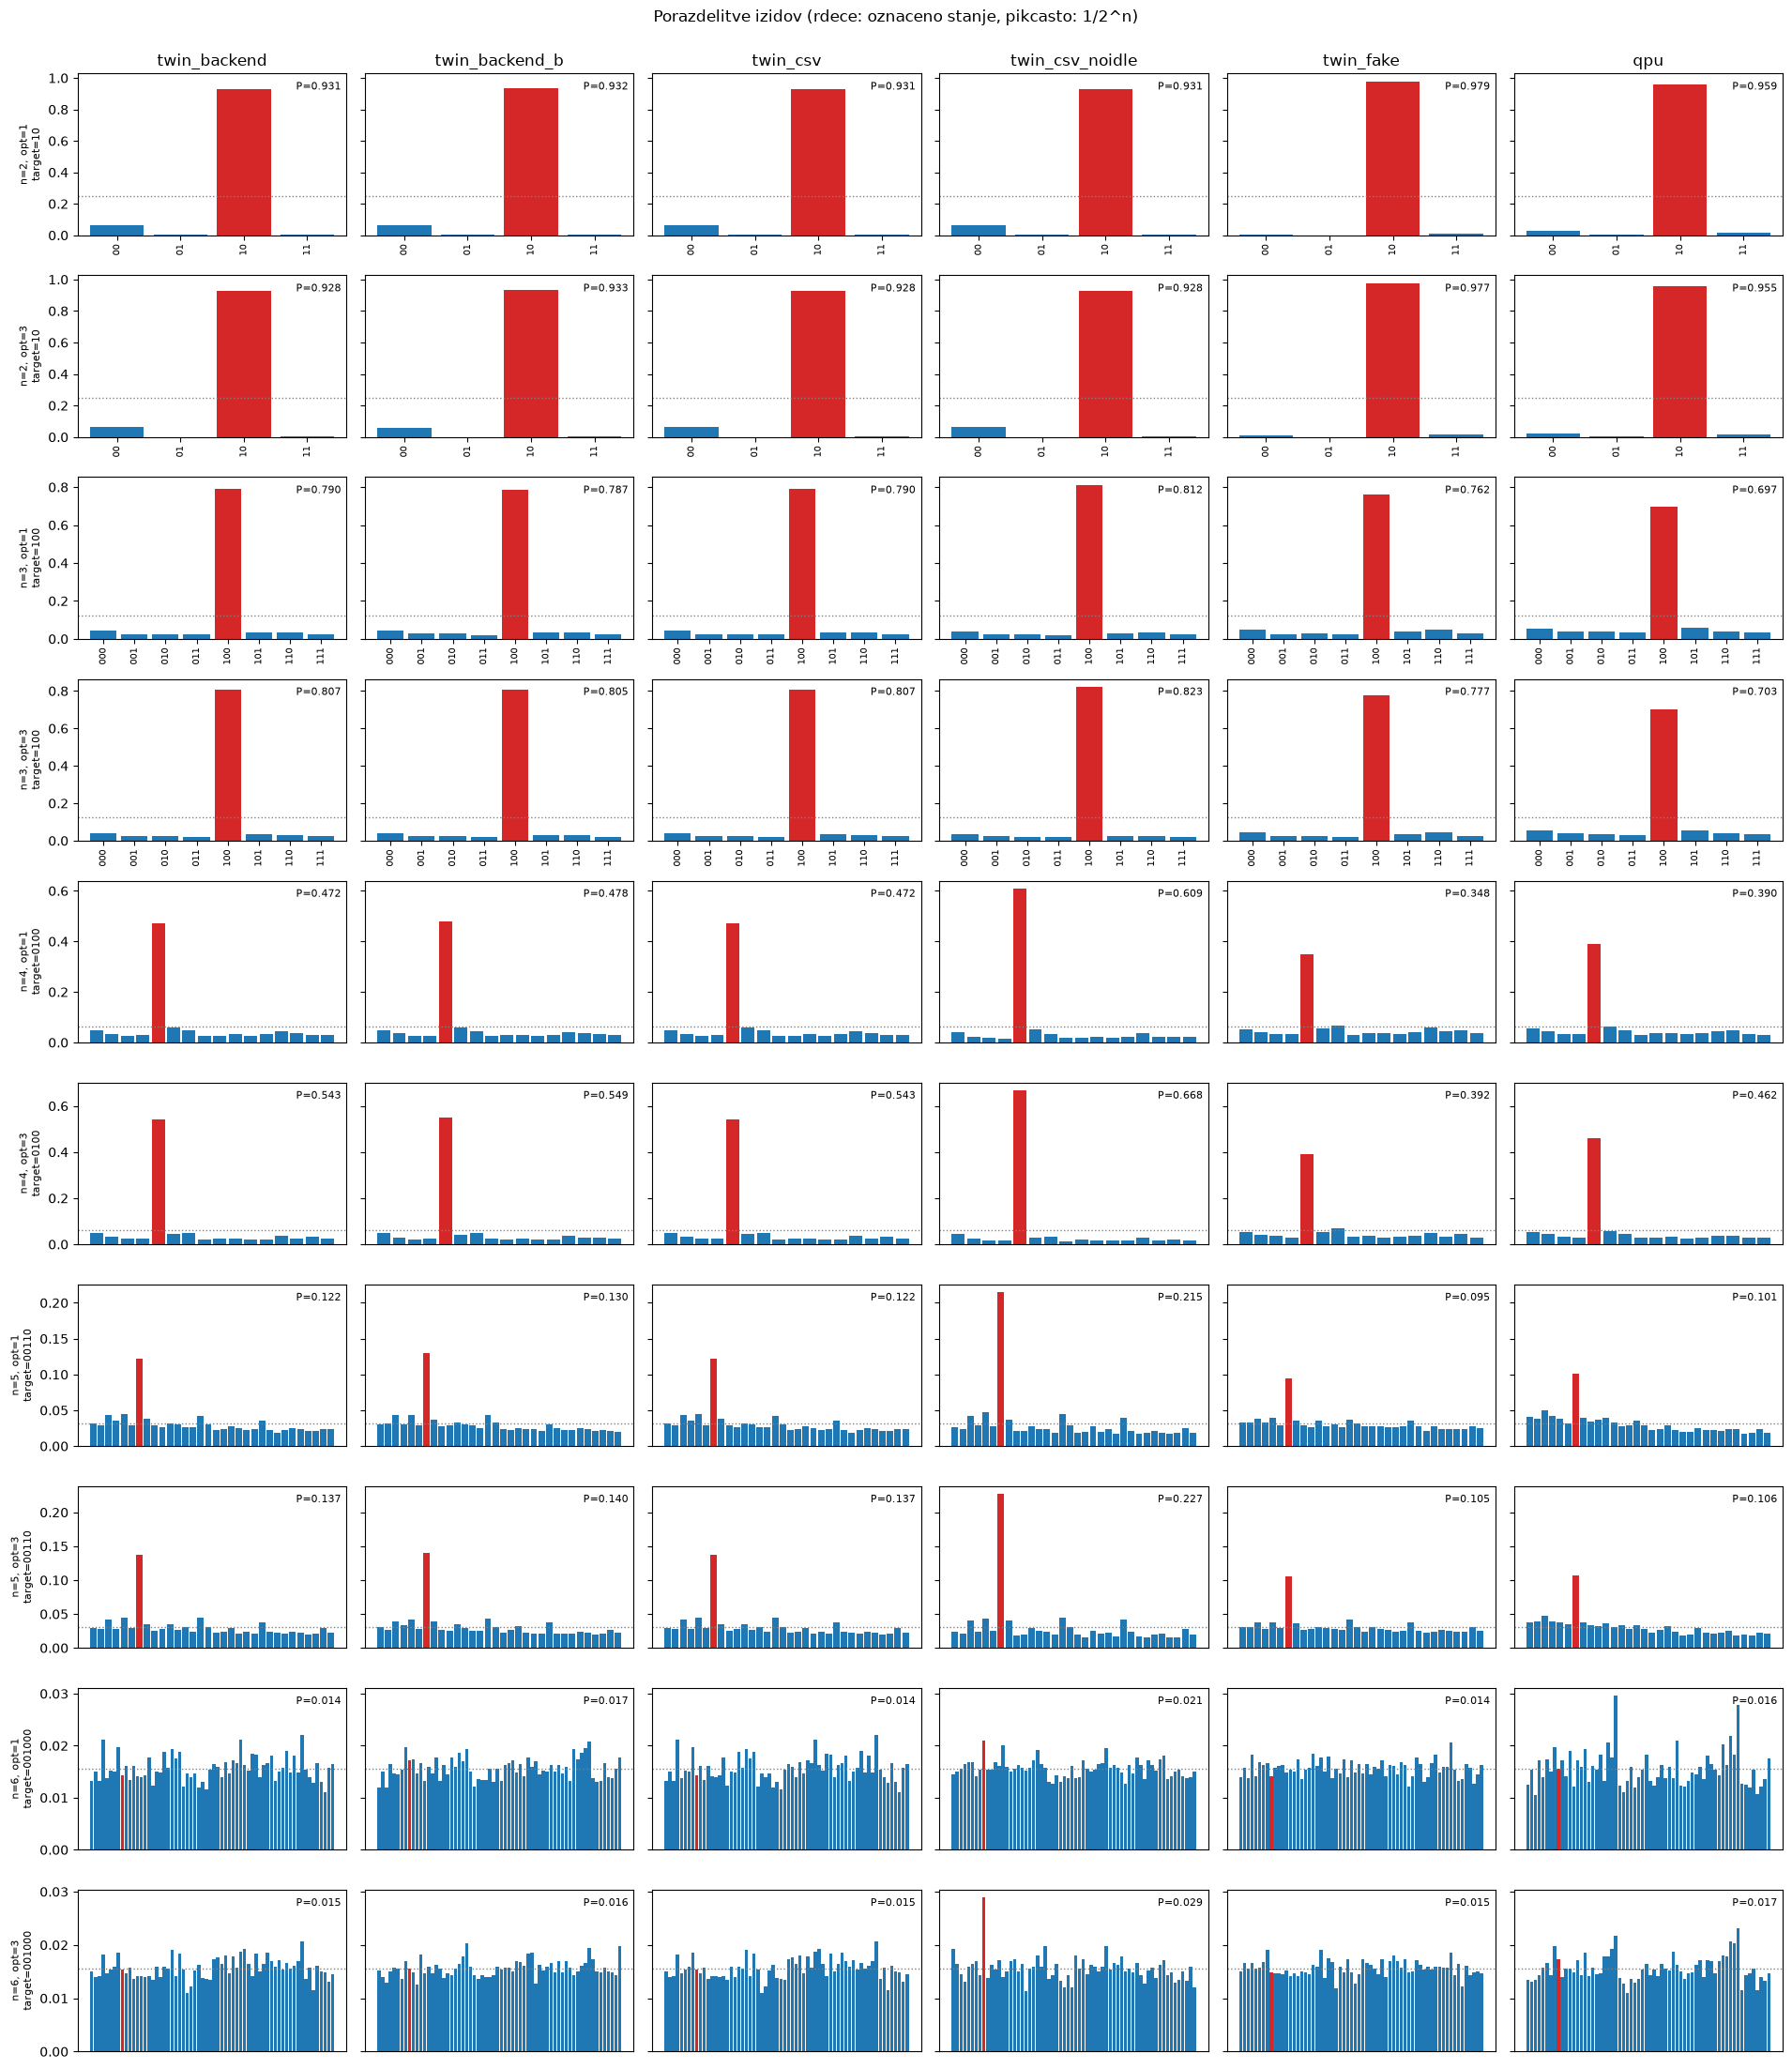

In [20]:
cols = [s for s in ["twin_backend", "twin_backend_b", "twin_csv", "twin_csv_noidle", "twin_fake", "qpu"]
        if s in results]
fig, axs = plt.subplots(len(items), len(cols), figsize=(3.2 * len(cols), 2.2 * len(items)),
                        sharey="row", squeeze=False)
for r, it in enumerate(items):
    n, t = it["n"], it["target"]
    states = [format(x, f"0{n}b") for x in range(2 ** n)]
    for c, name in enumerate(cols):
        counts = results[name][r]
        tot = sum(counts.values())
        p = [counts.get(s, 0) / tot for s in states]
        ax = axs[r][c]
        ax.bar(range(len(states)), p, width=0.85,
               color=["tab:red" if s == t else "tab:blue" for s in states])
        ax.axhline(1 / 2 ** n, color="gray", ls=":", lw=1)          # nakljucno
        ax.text(0.98, 0.95, f"P={counts.get(t, 0) / tot:.3f}", transform=ax.transAxes,
                ha="right", va="top", fontsize=8)
        if n <= 3:
            ax.set_xticks(range(len(states)), states, rotation=90, fontsize=7)
        else:
            ax.set_xticks([])
        if r == 0:
            ax.set_title(name)
        if c == 0:
            ax.set_ylabel(f"n={n}, opt={it['opt']}\ntarget={t}", fontsize=8)
fig.suptitle("Porazdelitve izidov (rdece: oznaceno stanje, pikcasto: 1/2^n)", y=1.0)
plt.tight_layout()

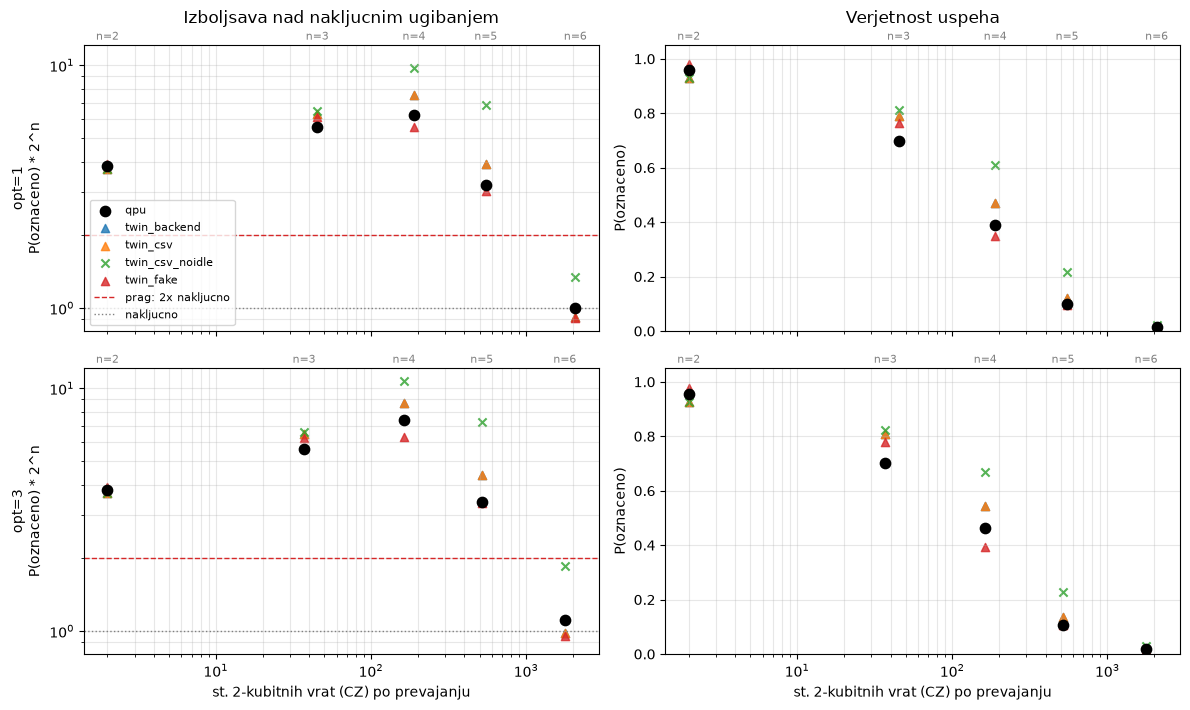

In [21]:
# P(oznaceno) v odvisnosti od stevila 2-kubitnih vrat po prevajanju; vrstica = optimizacijska stopnja.
# Levo: P * 2^n (kolikokrat bolje od nakljucnega ugibanja); prag "2x nakljucno" je vodoravna crta.
TAGS = []                    # npr. ["20261122-012230", "20261122-015016"] za dodatne zagone iz results/
frames = [pd.read_csv(out / f"{t}_summary.csv", dtype={"target": str}).assign(tag=t) for t in TAGS]
if "summary" in globals():
    frames.append(summary.assign(tag=TAG))
data = pd.concat(frames, ignore_index=True).drop_duplicates(subset=["tag", "n", "opt"])

show = [c for c in ["P_qpu", "P_twin_backend", "P_twin_csv", "P_twin_csv_noidle", "P_twin_fake"]
        if c in data and data[c].notna().any()]
style = {"P_qpu": dict(color="black", marker="o", s=55, zorder=5)}
opts = sorted(data["opt"].unique())
fig, axs = plt.subplots(len(opts), 2, figsize=(12, 3.6 * len(opts)), sharex=True, sharey="col",
                        squeeze=False)
for row, opt in zip(axs, opts):
    d = data[data["opt"] == opt]
    for c in show:
        kw = style.get(c, dict(marker="x" if "noidle" in c else "^", s=35, alpha=0.8))
        for ax, y in zip(row, (d[c] * 2 ** d["n"], d[c])):
            ax.scatter(d["two_q"], y, label=c[2:], **kw)
    for n, g in d.groupby("n"):                  # oznaka n ob zgornjem robu
        for ax in row:
            ax.text(g["two_q"].median(), 1.01, f"n={n}", transform=ax.get_xaxis_transform(),
                    ha="center", va="bottom", fontsize=8, color="gray")
    row[0].axhline(2, color="tab:red", ls="--", lw=1, label="prag: 2x nakljucno")
    row[0].axhline(1, color="gray", ls=":", lw=1, label="nakljucno")
    row[0].set(xscale="log", yscale="log", ylabel=f"opt={opt}\nP(oznaceno) * 2^n")
    row[1].set(xscale="log", ylabel="P(oznaceno)", ylim=(0, 1.05))
    for ax in row:
        ax.grid(alpha=0.3, which="both")
axs[0][0].set_title("Izboljsava nad nakljucnim ugibanjem", pad=16)
axs[0][1].set_title("Verjetnost uspeha", pad=16)
for ax in axs[-1]:
    ax.set_xlabel("st. 2-kubitnih vrat (CZ) po prevajanju")
axs[0][0].legend(fontsize=8)
plt.tight_layout()